# IA (XMCO01): Atividade de Aprendizado de Máquina

Este notebook apresenta o trabalho, explora o dataset **Bank Marketing**, cria os dois conjuntos de dados (`X_orig`, com `duration`, e `X_mod`, sem `duration`), aplica Random Forest, MLP e K-Means a ambos e compara os resultados. Execute as células em ordem.

## 1. Objetivo e conceitos

| Tarefa | Tipo | Modelo | Avaliação |
|---|---|---|---|
| Classificação | Supervisionado (com "gabarito") | Random Forest e MLP | `classification_report` + matriz de confusão |
| Agrupamento | Não supervisionado (sem "gabarito") | K-Means | Índice de Silhueta |

Todos os modelos serão aplicados ao conjunto **original** e ao **modificado**, e os resultados serão comparados.

## 2. Dataset

Banco português que ligava para clientes oferecendo um **depósito a prazo**. Cada linha é um cliente.
O alvo `y` indica se ele **aceitou** (`yes`) ou não (`no`). Arquivo: `bank-full.csv` (45.211 linhas, 16 atributos + `y`).

- **Numéricos:** `age`, `balance`, `day`, `duration` (duração da ligação em segundos), `campaign`, `pdays`, `previous`
- **Categóricos:** `job`, `marital`, `education`, `default`, `housing`, `loan`, `contact`, `month`, `poutcome`

In [2]:
import zipfile, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42   # mesma semente para o grupo todo (resultados repetíveis)
pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (8, 4)

def localizar_ou_baixar(nome="bank-full.csv"):
    """Procura o CSV por perto; se não achar, baixa da UCI."""
    for pasta in [Path("."), Path("/content"), Path("dados")]:
        if (pasta / nome).exists():
            return pasta / nome
    try:
        Path("dados").mkdir(exist_ok=True)
        urllib.request.urlretrieve("https://archive.ics.uci.edu/static/public/222/bank+marketing.zip",
                                   "dados/bank_marketing.zip")
        with zipfile.ZipFile("dados/bank_marketing.zip") as z: z.extractall("dados")
        with zipfile.ZipFile("dados/bank.zip") as z: z.extractall("dados")
        return Path("dados") / nome
    except Exception as e:
        raise FileNotFoundError(f"Download falhou ({e}). Baixe o zip em "
            "https://archive.ics.uci.edu/dataset/222/bank+marketing, extraia (há um bank.zip dentro) "
            "e coloque o bank-full.csv ao lado deste notebook.")

df = pd.read_csv(localizar_ou_baixar(), sep=";")   # separador é ';'
print(f"{df.shape[0]:,} linhas x {df.shape[1]} colunas")
df.head()

45,211 linhas x 17 colunas


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 3. Análise exploratória
### 3.1 Tipos de dados e valores `unknown`

In [3]:
alvo = "y"
cat_cols = df.drop(columns=alvo).select_dtypes(include="object").columns.tolist()
num_cols = df.drop(columns=alvo).select_dtypes(exclude="object").columns.tolist()
print("Numéricas  :", num_cols)
print("Categóricas:", cat_cols)
print("\nValores nulos no dataset:", int(df.isnull().sum().sum()))

# 'unknown' = informação não registrada (o pandas não o vê como nulo)
unk = (df[cat_cols] == "unknown").sum()
unk = unk[unk > 0].sort_values(ascending=False)
print("\nColunas com 'unknown':"); display(unk.to_frame("qtd").assign(pct=(unk / len(df) * 100).round(1)))

Numéricas  : ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Valores nulos no dataset: 0

Colunas com 'unknown':


,qtd,pct
poutcome,36959,81.7
contact,13020,28.8
education,1857,4.1
job,288,0.6


Não há nulos tradicionais. **Decisão:** manter `unknown` como uma categoria comum (também carrega informação e evita perder linhas).

### 3.2 Variável alvo e desbalanceamento

In [4]:
y = df["y"].map({"no": 0, "yes": 1})   # yes = 1 é a classe de interesse
print(df["y"].value_counts(normalize=True).mul(100).round(1).astype(str) + " %")

# "Modelo burro" que sempre responde 'no'
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score
pred = DummyClassifier(strategy="most_frequent").fit(df, y).predict(df)
print(f"\nSempre responder 'no' -> acurácia: {accuracy_score(y, pred):.1%} | recall de 'yes': {recall_score(y, pred):.1%}")

y
no     88.3 %
yes    11.7 %
Name: proportion, dtype: object

Sempre responder 'no' -> acurácia: 88.3% | recall de 'yes': 0.0%


**Conclusão:** o dataset é **desbalanceado** (~88% `no` / ~12% `yes`). Um modelo inútil já acerta ~88%, então a **acurácia engana**.
Nas análises, o foco será **recall, precision e F1 da classe `yes`** e a matriz de confusão.

### 3.3 Atributos numéricos e categóricos

,mean,std,min,50%,max
age,40.936210,10.618762,18.0,39.0,95.0
balance,1362.272058,3044.765829,-8019.0,448.0,102127.0
day,15.806419,8.322476,1.0,16.0,31.0
duration,258.163080,257.527812,0.0,180.0,4918.0
campaign,2.763841,3.098021,1.0,2.0,63.0
pdays,40.197828,100.128746,-1.0,-1.0,871.0
previous,0.580323,2.303441,0.0,0.0,275.0


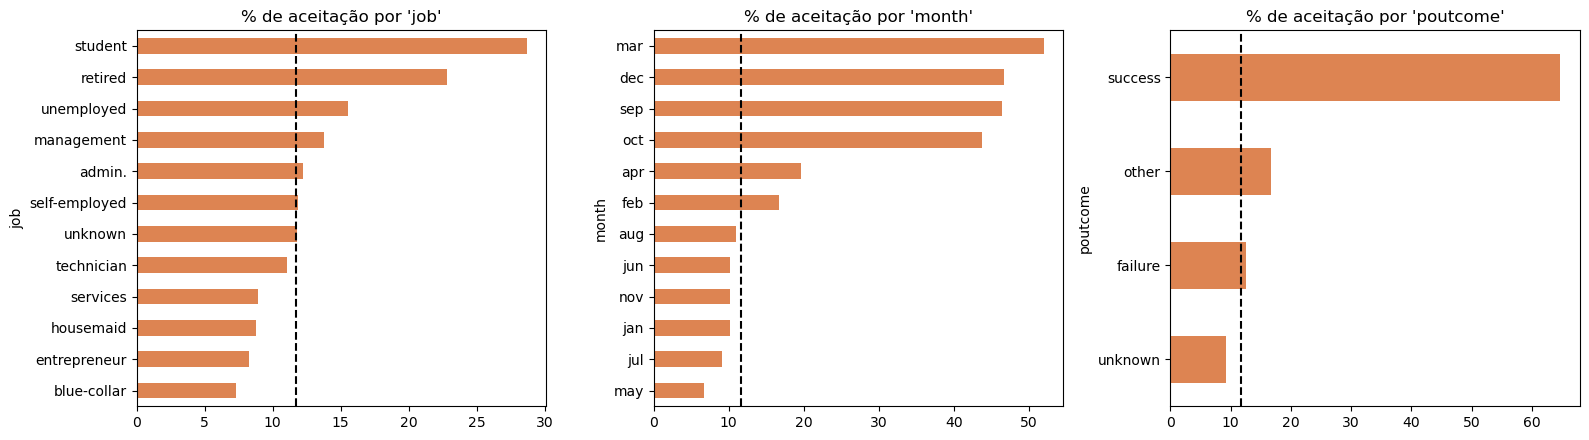

In [5]:
display(df[num_cols].describe().T[["mean", "std", "min", "50%", "max"]])

# Taxa de aceitação (% de 'yes') por categoria em alguns atributos
fig, eixos = plt.subplots(1, 3, figsize=(16, 4.5))
media = (df["y"] == "yes").mean() * 100
for ax, col in zip(eixos, ["job", "month", "poutcome"]):
    df.groupby(col)["y"].apply(lambda s: (s == "yes").mean() * 100).sort_values().plot(kind="barh", ax=ax, color="#dd8452")
    ax.axvline(media, color="black", ls="--"); ax.set_title(f"% de aceitação por '{col}'")
plt.tight_layout(); plt.show()

As escalas variam muito (`age` ~18-95; `balance` de negativos até >100 mil), por isso os dados serão **padronizados** na seção 6 (MLP e K-Means são sensíveis à escala).
A linha tracejada é a média geral: barras à direita aceitam mais que a média, então esses atributos ajudam a prever `y`.

## 4. O atributo `duration` e por que removê-lo

Duração média (s): {'no': 221.0, 'yes': 537.0}


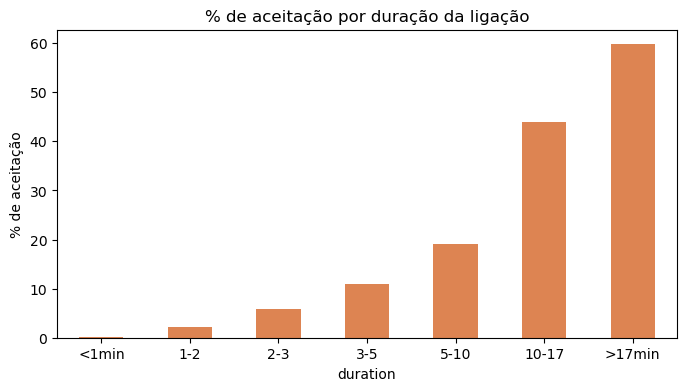

In [6]:
print("Duração média (s):", df.groupby("y")["duration"].mean().round(0).to_dict())

faixas = pd.cut(df["duration"], [-1, 60, 120, 180, 300, 600, 1000, df["duration"].max()],
                labels=["<1min", "1-2", "2-3", "3-5", "5-10", "10-17", ">17min"])
taxa = df.groupby(faixas, observed=True)["y"].apply(lambda s: (s == "yes").mean() * 100)
ax = taxa.plot(kind="bar", color="#dd8452", title="% de aceitação por duração da ligação")
ax.set_ylabel("% de aceitação"); plt.xticks(rotation=0); plt.show()

Quanto mais longa a ligação, maior a chance de aceitar. Parece ótimo, mas há uma armadilha:

> A duração **só é conhecida depois** da ligação, quando o resultado já é sabido. É como prever o jogo olhando o placar final (**data leakage**).

| Conjunto | Expectativa |
|---|---|
| **Original** (com `duration`) | Métricas altas, porém "infladas" |
| **Modificado** (sem `duration`) | Métricas menores, principalmente recall e F1 da classe `yes`, mas mais realistas |

## 5. Criando os dois conjuntos
`X` = características (entrada); `y` = alvo (resposta).

In [7]:
X_orig = df.drop(columns="y")                  # 16 colunas (com duration)
X_mod  = X_orig.drop(columns="duration")       # 15 colunas (sem duration)

# Verificações de segurança
assert "duration" in X_orig and "duration" not in X_mod and "y" not in X_orig
assert X_orig.shape[1] == X_mod.shape[1] + 1 and len(X_orig) == len(X_mod) == len(y)

num_orig = num_cols
num_mod  = [c for c in num_cols if c != "duration"]
print(f"X_orig: {X_orig.shape} | X_mod: {X_mod.shape} | y: {y.shape}  -> verificações OK ✔")
print("Numéricas (modificado):", num_mod)

X_orig: (45211, 16) | X_mod: (45211, 15) | y: (45211,)  -> verificações OK ✔
Numéricas (modificado): ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']


## 6. Pré-processamento e Divisão dos Dados

Os algoritmos de aprendizado de máquina não conseguem processar diretamente textos (variáveis categóricas) nem lidar bem com colunas numéricas de escalas muito discrepantes. Aplicamos:

- **One-Hot Encoding:** transforma as colunas categóricas de texto em colunas binárias (0/1).
- **Padronização (`StandardScaler`):** coloca as variáveis numéricas na mesma escala (média 0 e desvio padrão 1). É essencial para o MLP e o K-Means.
- **Divisão treino/teste:** 70% para treino e 30% para teste, com `stratify=y` (mantém a proporção da classe minoritária `yes`) e `random_state=42` (reprodutibilidade).

**Sem vazamento de dados:** primeiro dividimos, depois ajustamos (`fit`) o One-Hot e o padronizador **apenas com o treino**; o teste só é transformado (`transform`) com as médias e desvios do treino. Assim nenhuma informação do teste influencia o preparo dos dados.

**Equidade:** a divisão é feita por índices compartilhados, garantindo que exatamente os mesmos clientes sejam testados no conjunto original e no modificado.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

cat_cols = X_orig.select_dtypes(include="object").columns.tolist()
num_orig_cols = [c for c in X_orig.columns if c in num_cols]
num_mod_cols  = [c for c in X_mod.columns if c in num_cols]

def criar_preprocessador(colunas_num):
    return ColumnTransformer([
        ("num", StandardScaler(), colunas_num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])

preprocessor_orig = criar_preprocessador(num_orig_cols)
preprocessor_mod  = criar_preprocessador(num_mod_cols)

# Divisão por índices: os MESMOS clientes de treino/teste nos dois conjuntos
idx_train, idx_test = train_test_split(
    np.arange(len(y)), test_size=0.3, stratify=y, random_state=RANDOM_STATE
)

# fit só no TREINO; o teste apenas é transformado
X_train_orig = preprocessor_orig.fit_transform(X_orig.iloc[idx_train])
X_test_orig  = preprocessor_orig.transform(X_orig.iloc[idx_test])
X_train_mod  = preprocessor_mod.fit_transform(X_mod.iloc[idx_train])
X_test_mod   = preprocessor_mod.transform(X_mod.iloc[idx_test])
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]

print(f"Original  : treino {X_train_orig.shape} | teste {X_test_orig.shape}")
print(f"Modificado: treino {X_train_mod.shape} | teste {X_test_mod.shape}")
print(f"% de 'yes' -> treino: {y_train.mean():.1%} | teste: {y_test.mean():.1%}")

Original  : treino (31647, 51) | teste (13564, 51)
Modificado: treino (31647, 50) | teste (13564, 50)
% de 'yes' -> treino: 11.7% | teste: 11.7%


## 7. Classificação: Floresta Aleatória (Random Forest)

Uma **árvore de decisão** é um fluxograma de perguntas ("idade > 40? tem financiamento?...") que termina em uma resposta. A **floresta aleatória** cria várias árvores diferentes (cada uma vê uma amostra sorteada dos dados e dos atributos) e elas **votam**; a classe mais votada vence.

### 7.1 Parâmetros do `RandomForestClassifier`
| Parâmetro | O que faz | Valores usados |
|---|---|---|
| `n_estimators` | Número de árvores da floresta. Mais árvores costumam estabilizar o resultado, mas aumentam o tempo | `100`, `200` |
| `criterion` | Medida usada para escolher cada divisão: `gini` ou `entropy` | `gini` (padrão) |
| `max_depth` | Profundidade máxima de cada árvore. Árvores muito profundas tendem a decorar o treino (*overfitting*) | `10`, `None` (sem limite) |
| `min_samples_split` | Mínimo de amostras em um nó para ele poder se dividir | `2` (padrão) |
| `min_samples_leaf` | Mínimo de amostras em cada folha final. Valores maiores suavizam o modelo | `1` (padrão), `5` |
| `max_features` | Quantos atributos são sorteados a cada divisão (é o que torna as árvores diferentes entre si) | `sqrt` (padrão) |
| `class_weight` | Peso das classes. `balanced` dá mais peso à classe rara (`yes`), compensando o desbalanceamento | `None`, `balanced`, `balanced_subsample` |
| `n_jobs` | Número de núcleos do processador usados (`-1` = todos) | `-1` |
| `random_state` | Semente dos sorteios, para resultados reproduzíveis | `42` |

> A Random Forest **não precisa** de padronização, mas usamos os mesmos dados pré-processados dos outros modelos para a comparação ser justa.

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score)
from IPython.display import Markdown, display

fmt = lambda v: f"{v:.3f}".replace(".", ",")      # número no formato brasileiro
fmt4 = lambda v: f"{v:.4f}".replace(".", ",")
fms = lambda v: f"{v:+.3f}".replace(".", ",")      # com sinal
fms4 = lambda v: f"{v:+.4f}".replace(".", ",")
COLS = ["Acurácia", "Precision (yes)", "Recall (yes)", "F1 (yes)", "F1 macro"]

def comparar(resultados, titulo_graf):
    """Monta a tabela original x modificado (+ variação) e o gráfico de recall/F1 do 'yes'."""
    tab = pd.DataFrame(resultados)
    o = tab[tab["Conjunto"] == "Original"].set_index("Configuração")[COLS]
    m = tab[tab["Conjunto"] == "Modificado"].set_index("Configuração")[COLS]
    display(pd.concat({"Original (com duration)": o, "Modificado (sem duration)": m,
                       "Variação (mod - orig)": m - o}, axis=1).round(3))
    fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
    for ax, metrica in zip(eixos, ["Recall (yes)", "F1 (yes)"]):
        pd.DataFrame({"Original": o[metrica], "Modificado": m[metrica]}).plot(
            kind="bar", ax=ax, color=["#4c72b0", "#dd8452"], rot=15)
        ax.set_title(f"{titulo_graf}: {metrica}"); ax.set_ylim(0, 1); ax.set_xlabel("")
    plt.tight_layout(); plt.show()
    return tab, o, m

### 7.2 Função de treino e configurações testadas
Para rodar vários testes mudando **apenas os valores dos parâmetros**, o código fica em uma função. Três configurações, sem busca exaustiva:

- **A – Base:** 100 árvores, `max_depth=10`, sem tratar o desbalanceamento.
- **B – Balanceada:** 200 árvores, `max_depth=10`, `class_weight="balanced"` (isola o efeito do peso das classes).
- **C – Mais profunda e balanceada:** 200 árvores, sem limite de profundidade, `min_samples_leaf=5` (evita folhas minúsculas) e `class_weight="balanced_subsample"`.

In [10]:
def treinar_rf(X_train, X_test, y_train, y_test, rotulo, mostrar_relatorio=True, **params):
    """Treina uma Random Forest com os parâmetros recebidos e avalia no teste."""
    modelo = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **params)
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)

    if mostrar_relatorio:
        print(f"=== {rotulo} ===")
        print(classification_report(y_test, y_pred, target_names=["no (0)", "yes (1)"], digits=3))

    metricas = {
        "Acurácia": accuracy_score(y_test, y_pred),
        "Precision (yes)": precision_score(y_test, y_pred, zero_division=0),
        "Recall (yes)": recall_score(y_test, y_pred),
        "F1 (yes)": f1_score(y_test, y_pred),
        "F1 macro": f1_score(y_test, y_pred, average="macro"),
    }
    return modelo, y_pred, metricas

configuracoes_rf = {
    "A - Base (100, depth 10)": dict(n_estimators=100, max_depth=10),
    "B - Balanceada (200, depth 10)": dict(n_estimators=200, max_depth=10, class_weight="balanced"),
    "C - Profunda balanceada (200)": dict(n_estimators=200, max_depth=None, min_samples_leaf=5,
                                          class_weight="balanced_subsample"),
}
conjuntos = {
    "Original":   (X_train_orig, X_test_orig),
    "Modificado": (X_train_mod, X_test_mod),
}

### 7.3 Resultados: relatório de métricas
O foco é a classe `yes` (minoritária): olhe **recall** (quantos dos clientes que aceitariam foram encontrados), **precision** (quando o modelo diz `yes`, quantas vezes acerta) e **F1**, não a acurácia.

In [11]:
resultados_rf, previsoes_rf, modelos_rf = [], {}, {}

for nome_cfg, params in configuracoes_rf.items():
    for nome_conj, (Xtr, Xte) in conjuntos.items():
        modelo, y_pred, met = treinar_rf(Xtr, Xte, y_train, y_test, f"{nome_cfg} | {nome_conj}", **params)
        met["Configuração"], met["Conjunto"] = nome_cfg, nome_conj
        resultados_rf.append(met)
        previsoes_rf[(nome_cfg, nome_conj)] = y_pred
        modelos_rf[(nome_cfg, nome_conj)] = modelo

=== A - Base (100, depth 10) | Original ===
              precision    recall  f1-score   support

      no (0)      0.902     0.992     0.945     11977
     yes (1)      0.756     0.189     0.302      1587

    accuracy                          0.898     13564
   macro avg      0.829     0.590     0.624     13564
weighted avg      0.885     0.898     0.870     13564

=== A - Base (100, depth 10) | Modificado ===
              precision    recall  f1-score   support

      no (0)      0.901     0.992     0.944     11977
     yes (1)      0.734     0.176     0.284      1587

    accuracy                          0.896     13564
   macro avg      0.817     0.584     0.614     13564
weighted avg      0.881     0.896     0.867     13564

=== B - Balanceada (200, depth 10) | Original ===
              precision    recall  f1-score   support

      no (0)      0.976     0.848     0.908     11977
     yes (1)      0.424     0.844     0.564      1587

    accuracy                          0.84

### 7.4 Resultados: matrizes de confusão
Linha = classe real, coluna = classe prevista. O canto inferior esquerdo (real `yes`, previsto `no`) são os **falsos negativos**: clientes que aceitariam, mas o modelo não identificou.

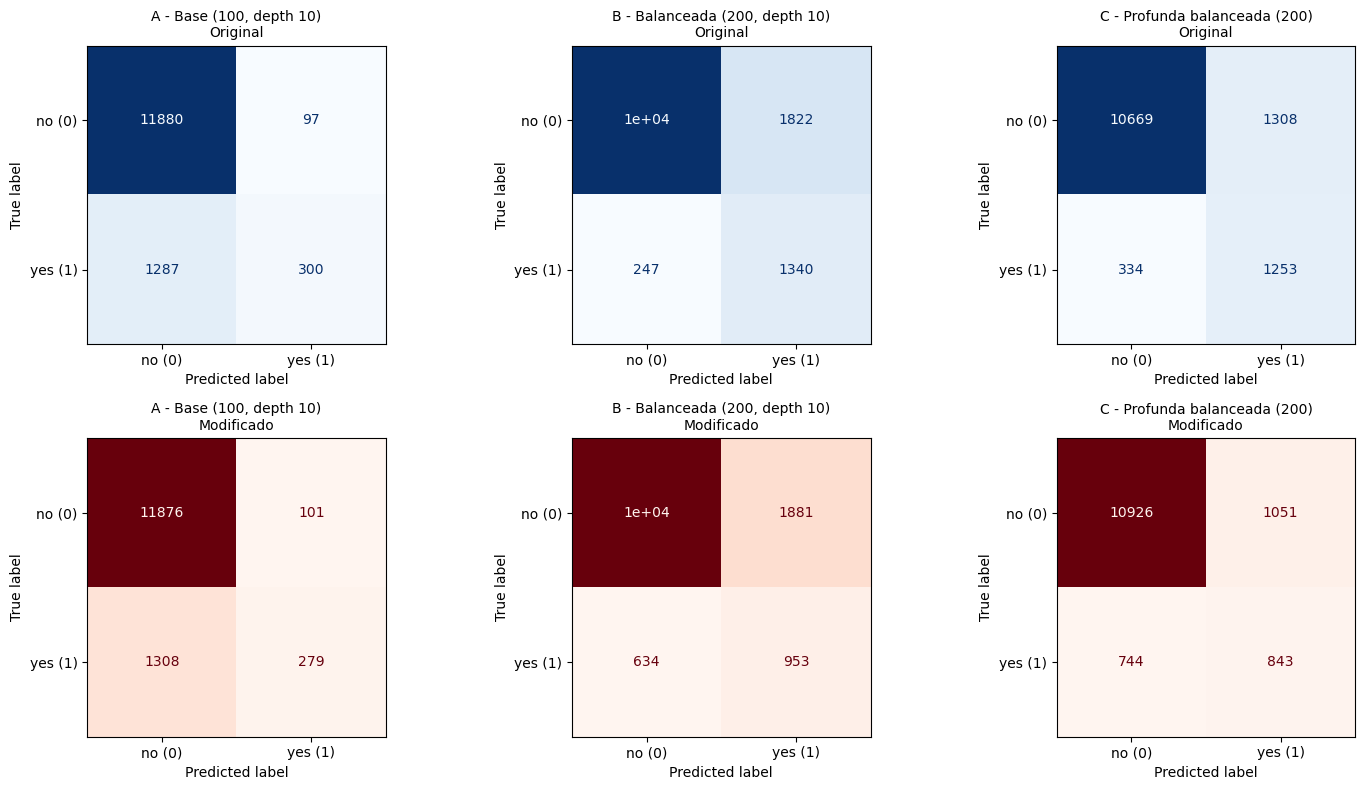

In [12]:
fig, eixos = plt.subplots(2, 3, figsize=(15, 8))
for j, nome_cfg in enumerate(configuracoes_rf):
    for i, (nome_conj, cmap) in enumerate([("Original", "Blues"), ("Modificado", "Reds")]):
        ConfusionMatrixDisplay.from_predictions(
            y_test, previsoes_rf[(nome_cfg, nome_conj)], display_labels=["no (0)", "yes (1)"],
            cmap=cmap, colorbar=False, ax=eixos[i, j])
        eixos[i, j].set_title(f"{nome_cfg}\n{nome_conj}", fontsize=10)
plt.tight_layout()
plt.show()

### 7.5 Comparação: original × modificado
Métricas lado a lado e a variação ao remover `duration`.

Original (com duration)                  \
                                              Acurácia Precision (yes)   
Configuração                                                             
A - Base (100, depth 10)                         0.898           0.756   
B - Balanceada (200, depth 10)                   0.847           0.424   
C - Profunda balanceada (200)                    0.879           0.489   

                                                               \
                               Recall (yes) F1 (yes) F1 macro   
Configuração                                                    
A - Base (100, depth 10)              0.189    0.302    0.624   
B - Balanceada (200, depth 10)        0.844    0.564    0.736   
C - Profunda balanceada (200)         0.790    0.604    0.766   

                               Modificado (sem duration)                  \
                                                Acurácia Precision (yes)   
Configuração                                                               
A - Base (100, depth 10)                           0.896           0.734   
B - Balanceada (200, depth 10)                     0.815           0.336   
C - Profunda balanceada (200)                      0.868           0.445   

                                                               \
                               Recall (yes) F1 (yes) F1 macro   
Configuração                                                    
A - Base (100, depth 10)              0.176    0.284    0.614   
B - Balanceada (200, depth 10)        0.601    0.431    0.660   
C - Profunda balanceada (200)         0.531    0.484    0.704   

                               Variação (mod - orig)                  \
                                            Acurácia Precision (yes)   
Configuração                                                           
A - Base (100, depth 10)                      -0.002          -0.021   
B - Balanceada (200, depth 10)                -0.033          -0.088   
C - Profunda balanceada (200)                 -0.011          -0.044   

                                                               
                               Recall (yes) F1 (yes) F1 macro  
Configuração                                                   
A - Base (100, depth 10)             -0.013   -0.019   -0.010  
B - Balanceada (200, depth 10)       -0.244   -0.133   -0.076  
C - Profunda balanceada (200)        -0.258   -0.120   -0.062

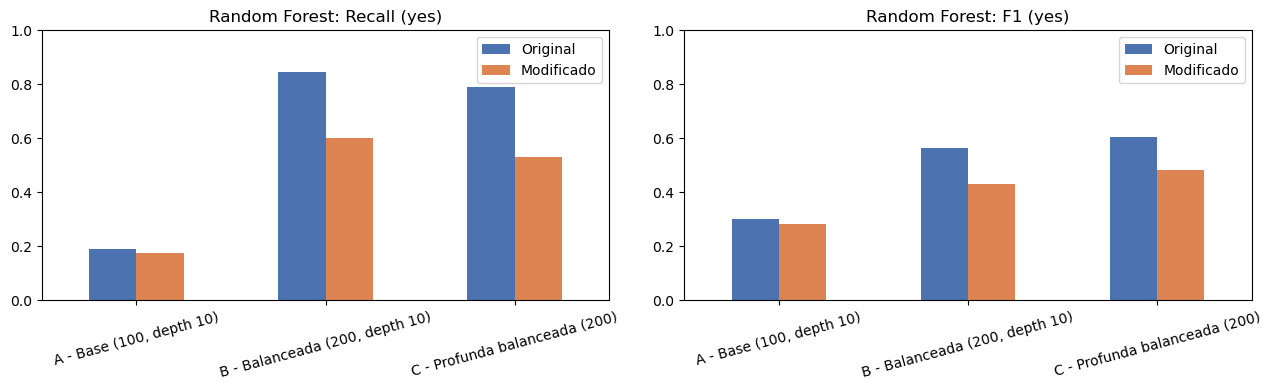

In [13]:
tab_rf, orig_rf, mod_rf = comparar(resultados_rf, "Random Forest")

### 7.6 O `duration` importa para a floresta?
A Random Forest calcula a **importância** de cada atributo (o quanto ele ajudou a dividir bem os dados). Usamos a configuração com melhor F1 do `yes` no conjunto modificado, que também será a usada na comparação final (seção 10).

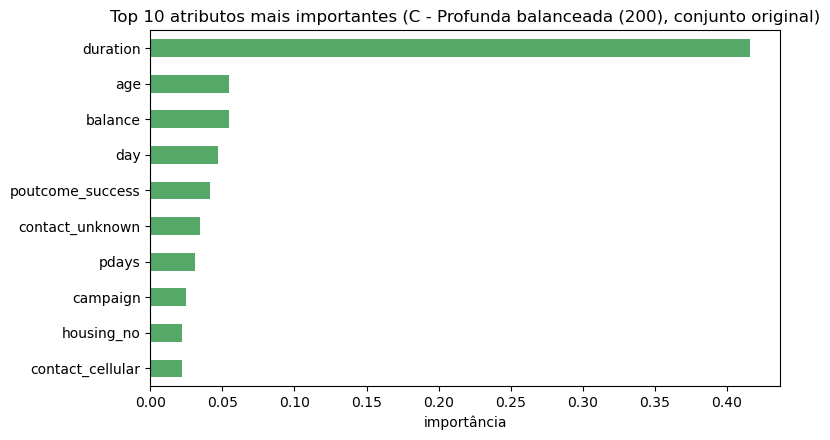

'duration' é o 1º atributo mais importante, com 41.6% da importância total.


In [14]:
# Configuração final do RF: maior F1 do 'yes' no conjunto modificado (cenário realista)
cfg_rf_final = mod_rf["F1 (yes)"].idxmax()
modelo_imp = modelos_rf[(cfg_rf_final, "Original")]

imp = pd.Series(modelo_imp.feature_importances_,
                index=preprocessor_orig.get_feature_names_out()).sort_values(ascending=False)
imp.index = [n.replace("num__", "").replace("cat__", "") for n in imp.index]

pos_dur = list(imp.index).index("duration") + 1
parte_dur = imp["duration"]

ax = imp.head(10).sort_values().plot(kind="barh", color="#55a868", figsize=(8, 4.5),
                                     title=f"Top 10 atributos mais importantes ({cfg_rf_final}, conjunto original)")
ax.set_xlabel("importância")
plt.tight_layout(); plt.show()
print(f"'duration' é o {pos_dur}º atributo mais importante, com {parte_dur:.1%} da importância total.")

In [15]:
base = 1 - y_test.mean()                       # acurácia de um modelo que sempre responde 'no'
nomes_rf = list(configuracoes_rf)
cfg_base, cfg_bal = nomes_rf[0], nomes_rf[1]
rec_o, rec_m = orig_rf["Recall (yes)"], mod_rf["Recall (yes)"]
f1_o, f1_m = orig_rf["F1 (yes)"], mod_rf["F1 (yes)"]
sentido = "cai" if rec_m.mean() < rec_o.mean() else "aumenta"

d_rec = mod_rf.loc[cfg_bal, "Recall (yes)"] - mod_rf.loc[cfg_base, "Recall (yes)"]
d_pre = mod_rf.loc[cfg_bal, "Precision (yes)"] - mod_rf.loc[cfg_base, "Precision (yes)"]
efeito_cw = ("aumentou o recall e reduziu a precision: o modelo passa a marcar `yes` com mais frequência, "
             "encontrando mais clientes que aceitariam ao custo de mais falsos alarmes"
             if (d_rec > 0 and d_pre < 0) else "alterou as métricas conforme mostra a tabela")

display(Markdown(f'''
### 7.7 Análise dos resultados (Random Forest)

**1. Acurácia engana.** Ficou entre {fmt(tab_rf["Acurácia"].min())} e {fmt(tab_rf["Acurácia"].max())} nas seis combinações, enquanto um modelo que sempre responde `no` teria {fmt(base)}. A diferença real aparece no recall e no F1 do `yes`.

**2. Efeito de remover `duration`.** O recall do `yes` {sentido} de {fmt(rec_o.min())}–{fmt(rec_o.max())} (original) para {fmt(rec_m.min())}–{fmt(rec_m.max())} (modificado), e o F1 do `yes` vai de {fmt(f1_o.min())}–{fmt(f1_o.max())} para {fmt(f1_m.min())}–{fmt(f1_m.max())}. Na importância dos atributos, `duration` aparece em **{pos_dur}º lugar** ({parte_dur:.1%} do total) na configuração {cfg_rf_final}.

**3. Efeito do `class_weight`.** Comparando A com B (mesma profundidade, muda só o peso das classes), no conjunto modificado o recall foi de {fmt(mod_rf.loc[cfg_base, "Recall (yes)"])} para {fmt(mod_rf.loc[cfg_bal, "Recall (yes)"])} e a precision de {fmt(mod_rf.loc[cfg_base, "Precision (yes)"])} para {fmt(mod_rf.loc[cfg_bal, "Precision (yes)"])}. O `class_weight="balanced"` {efeito_cw}.

**4. Melhor configuração.** Pelo F1 do `yes`, a melhor no conjunto original foi **{f1_o.idxmax()}** e, no modificado, **{f1_m.idxmax()}**.

**Ressalva:** escolhemos a configuração olhando o próprio conjunto de teste, o que é levemente otimista. Em um projeto real, usaríamos um conjunto de validação separado.
'''))


### 7.7 Análise dos resultados (Random Forest)

**1. Acurácia engana.** Ficou entre 0,815 e 0,898 nas seis combinações, enquanto um modelo que sempre responde `no` teria 0,883. A diferença real aparece no recall e no F1 do `yes`.

**2. Efeito de remover `duration`.** O recall do `yes` cai de 0,189–0,844 (original) para 0,176–0,601 (modificado), e o F1 do `yes` vai de 0,302–0,604 para 0,284–0,484. Na importância dos atributos, `duration` aparece em **1º lugar** (41.6% do total) na configuração C - Profunda balanceada (200).

**3. Efeito do `class_weight`.** Comparando A com B (mesma profundidade, muda só o peso das classes), no conjunto modificado o recall foi de 0,176 para 0,601 e a precision de 0,734 para 0,336. O `class_weight="balanced"` aumentou o recall e reduziu a precision: o modelo passa a marcar `yes` com mais frequência, encontrando mais clientes que aceitariam ao custo de mais falsos alarmes.

**4. Melhor configuração.** Pelo F1 do `yes`, a melhor no conjunto original foi **C - Profunda balanceada (200)** e, no modificado, **C - Profunda balanceada (200)**.

**Ressalva:** escolhemos a configuração olhando o próprio conjunto de teste, o que é levemente otimista. Em um projeto real, usaríamos um conjunto de validação separado.


## 8. Classificação: Perceptron de Múltiplas Camadas (MLP)
Nesta seção aplicamos o `MLPClassifier` do scikit-learn ao conjunto **original** (com `duration`) e ao **modificado** (sem `duration`), usando a mesma divisão treino/teste da seção 6.

O MLP é uma rede neural: os atributos entram na primeira camada, passam por uma ou mais **camadas ocultas** (cada neurônio faz uma soma ponderada seguida de uma função de ativação) e a camada de saída dá a probabilidade de `yes`. Os pesos são ajustados por gradiente para reduzir o erro. Por isso o MLP **exige dados padronizados**, o que já foi feito no pré-processamento.

### 8.1 Parâmetros do `MLPClassifier`
| Parâmetro | O que faz | Valores testados |
|---|---|---|
| `hidden_layer_sizes` | Número de camadas ocultas e de neurônios em cada uma, ex.: `(64,)` = 1 camada com 64; `(128, 64)` = 2 camadas | `(64,)`, `(128, 64)`, `(64, 32)` |
| `activation` | Função de ativação dos neurônios: `relu`, `tanh` ou `logistic` | `relu`, `tanh` |
| `solver` | Algoritmo de otimização dos pesos: `adam` (padrão, bom em dados grandes), `sgd` ou `lbfgs` (melhor em bases pequenas) | `adam` |
| `alpha` | Regularização L2: penaliza pesos grandes e reduz *overfitting* | `1e-4`, `1e-3`, `1e-2` |
| `learning_rate_init` | Tamanho do passo de atualização dos pesos. Alto demais oscila; baixo demais demora | `1e-3`, `5e-4` |
| `max_iter` | Número máximo de épocas (passadas completas pelo treino) | `200` |
| `early_stopping` | Separa 10% do treino para validação e para quando a pontuação deixa de melhorar. Evita overfitting e acelera | `True` |
| `batch_size` | Tamanho do mini-lote por atualização (padrão `min(200, n_amostras)`) | padrão (200) |
| `random_state` | Fixa a semente (pesos iniciais e embaralhamento) para resultados reproduzíveis | `42` |

> O `MLPClassifier` **não tem** `class_weight`, então o desbalanceamento (~88% `no` / ~12% `yes`) não é compensado automaticamente. Isso tende a limitar o recall da classe `yes`.

### 8.2 Função de treino e avaliação
Para rodar vários testes mudando **apenas os valores dos parâmetros**, o código fica em uma função: ela treina o MLP, calcula as métricas no conjunto de teste, imprime o `classification_report` e devolve o modelo, as previsões e as métricas da classe `yes`.

In [16]:
import warnings
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)   # avisos de convergência não poluem a apresentação

def treinar_mlp(X_train, X_test, y_train, y_test, rotulo, mostrar_relatorio=True, **params):
    """Treina um MLPClassifier com os parâmetros recebidos e avalia no teste."""
    modelo = MLPClassifier(random_state=RANDOM_STATE, **params)
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)

    if mostrar_relatorio:
        print(f"=== {rotulo} ===")
        print(classification_report(y_test, y_pred, target_names=["no (0)", "yes (1)"], digits=3))

    metricas = {
        "Acurácia": accuracy_score(y_test, y_pred),
        "Precision (yes)": precision_score(y_test, y_pred, zero_division=0),
        "Recall (yes)": recall_score(y_test, y_pred),
        "F1 (yes)": f1_score(y_test, y_pred),
        "F1 macro": f1_score(y_test, y_pred, average="macro"),
        "Épocas": modelo.n_iter_,
    }
    return modelo, y_pred, metricas

### 8.3 Configurações testadas
Três configurações bem escolhidas, sem busca exaustiva, para variar o que mais influencia o MLP:

- **A – Base:** 1 camada de 64 neurônios, `relu`, `alpha=1e-4`. Ponto de partida simples.
- **B – Mais profunda:** 2 camadas `(128, 64)`, `relu`, `alpha=1e-3`. Mais capacidade de aprendizado.
- **C – `tanh` + mais regularização:** `(64, 32)`, `tanh`, `alpha=1e-2`, taxa de aprendizado menor (`5e-4`). Testa outra ativação e maior regularização.

Todas usam `solver='adam'`, `max_iter=200` e `early_stopping=True`.

In [17]:
configuracoes_mlp = {
    "A - Base (64, relu)": dict(hidden_layer_sizes=(64,), activation="relu", solver="adam",
                                alpha=1e-4, learning_rate_init=1e-3, max_iter=200, early_stopping=True),
    "B - Profunda (128,64, relu)": dict(hidden_layer_sizes=(128, 64), activation="relu", solver="adam",
                                        alpha=1e-3, learning_rate_init=1e-3, max_iter=200, early_stopping=True),
    "C - tanh + reg. (64,32)": dict(hidden_layer_sizes=(64, 32), activation="tanh", solver="adam",
                                    alpha=1e-2, learning_rate_init=5e-4, max_iter=200, early_stopping=True),
}
conjuntos = {
    "Original": (X_train_orig, X_test_orig),
    "Modificado": (X_train_mod, X_test_mod),
}

### 8.4 Resultados: relatório de métricas
Para cada configuração, o `classification_report` do conjunto **original** e do **modificado**. O foco é a classe `yes` (minoritária): olhe **recall** (quantos dos clientes que aceitariam foram encontrados) e **F1**, não a acurácia.

In [18]:
resultados_mlp, previsoes_mlp = [], {}

for nome_cfg, params in configuracoes_mlp.items():
    for nome_conj, (Xtr, Xte) in conjuntos.items():
        modelo, y_pred, met = treinar_mlp(Xtr, Xte, y_train, y_test, f"{nome_cfg} | {nome_conj}", **params)
        met["Configuração"], met["Conjunto"] = nome_cfg, nome_conj
        resultados_mlp.append(met)
        previsoes_mlp[(nome_cfg, nome_conj)] = y_pred

=== A - Base (64, relu) | Original ===
              precision    recall  f1-score   support

      no (0)      0.929     0.965     0.947     11977
     yes (1)      0.630     0.446     0.523      1587

    accuracy                          0.905     13564
   macro avg      0.780     0.706     0.735     13564
weighted avg      0.894     0.905     0.897     13564

=== A - Base (64, relu) | Modificado ===
              precision    recall  f1-score   support

      no (0)      0.904     0.986     0.943     11977
     yes (1)      0.665     0.212     0.322      1587

    accuracy                          0.895     13564
   macro avg      0.784     0.599     0.633     13564
weighted avg      0.876     0.895     0.871     13564

=== B - Profunda (128,64, relu) | Original ===
              precision    recall  f1-score   support

      no (0)      0.943     0.952     0.947     11977
     yes (1)      0.609     0.566     0.587      1587

    accuracy                          0.907     13564
 

### 8.5 Resultados: matrizes de confusão
Linha = classe real, coluna = classe prevista. O canto inferior esquerdo (real `yes`, previsto `no`) são os **falsos negativos**: clientes que aceitariam, mas o modelo não identificou.

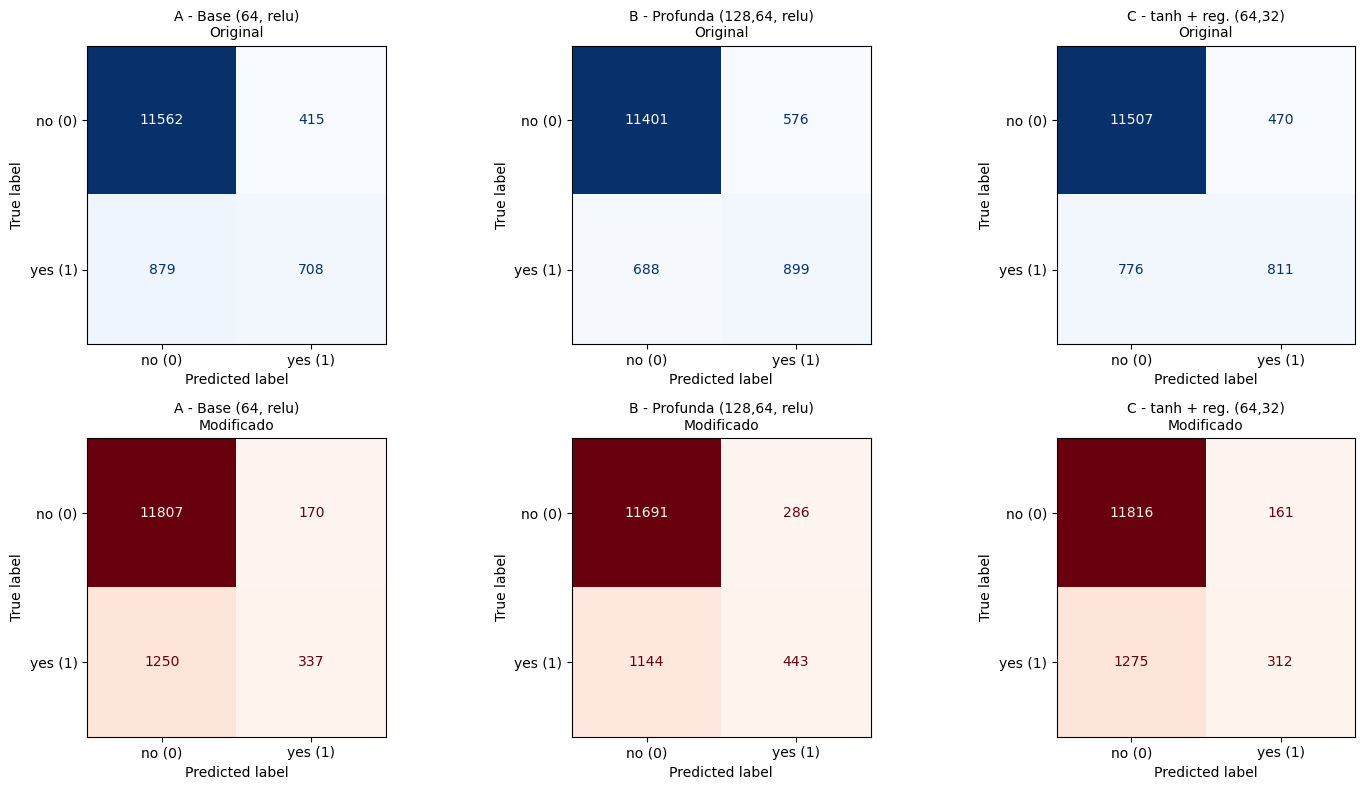

In [19]:
fig, eixos = plt.subplots(2, 3, figsize=(15, 8))
for j, nome_cfg in enumerate(configuracoes_mlp):
    for i, (nome_conj, cmap) in enumerate([("Original", "Blues"), ("Modificado", "Reds")]):
        ConfusionMatrixDisplay.from_predictions(
            y_test, previsoes_mlp[(nome_cfg, nome_conj)], display_labels=["no (0)", "yes (1)"],
            cmap=cmap, colorbar=False, ax=eixos[i, j])
        eixos[i, j].set_title(f"{nome_cfg}\n{nome_conj}", fontsize=10)
plt.tight_layout()
plt.show()

### 8.6 Comparação: original × modificado
Métricas da classe `yes` lado a lado, variação ao remover `duration` e número de épocas que cada treino precisou (o `early_stopping` pode parar antes de `max_iter`).

Original (com duration)                  \
                                           Acurácia Precision (yes)   
Configuração                                                          
A - Base (64, relu)                           0.905           0.630   
B - Profunda (128,64, relu)                   0.907           0.609   
C - tanh + reg. (64,32)                       0.908           0.633   

                                                            \
                            Recall (yes) F1 (yes) F1 macro   
Configuração                                                 
A - Base (64, relu)                0.446    0.523    0.735   
B - Profunda (128,64, relu)        0.566    0.587    0.767   
C - tanh + reg. (64,32)            0.511    0.566    0.757   

                            Modificado (sem duration)                  \
                                             Acurácia Precision (yes)   
Configuração                                                            
A - Base (64, relu)                             0.895           0.665   
B - Profunda (128,64, relu)                     0.895           0.608   
C - tanh + reg. (64,32)                         0.894           0.660   

                                                            \
                            Recall (yes) F1 (yes) F1 macro   
Configuração                                                 
A - Base (64, relu)                0.212    0.322    0.633   
B - Profunda (128,64, relu)        0.279    0.383    0.662   
C - tanh + reg. (64,32)            0.197    0.303    0.623   

                            Variação (mod - orig)                  \
                                         Acurácia Precision (yes)   
Configuração                                                        
A - Base (64, relu)                        -0.009           0.034   
B - Profunda (128,64, relu)                -0.012          -0.002   
C - tanh + reg. (64,32)                    -0.014           0.027   

                                                            
                            Recall (yes) F1 (yes) F1 macro  
Configuração                                                
A - Base (64, relu)               -0.234   -0.201   -0.102  
B - Profunda (128,64, relu)       -0.287   -0.205   -0.105  
C - tanh + reg. (64,32)           -0.314   -0.263   -0.134

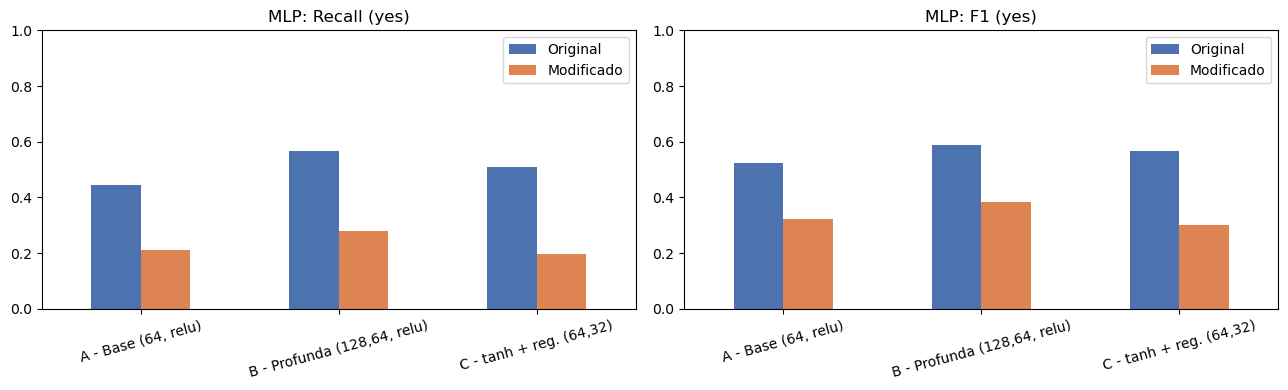

Épocas de treino,Modificado,Original
Configuração,,
"A - Base (64, relu)",24,20
"B - Profunda (128,64, relu)",18,19
"C - tanh + reg. (64,32)",29,39


In [20]:
tab_mlp, orig_mlp, mod_mlp = comparar(resultados_mlp, "MLP")
display(pd.DataFrame(resultados_mlp).pivot(index="Configuração", columns="Conjunto", values="Épocas")
        .rename_axis(columns="Épocas de treino"))

In [21]:
cfg_mlp_final = mod_mlp["F1 (yes)"].idxmax()     # melhor F1 do 'yes' no conjunto modificado (cenário realista)
rec_o, rec_m = orig_mlp["Recall (yes)"], mod_mlp["Recall (yes)"]
f1_o, f1_m = orig_mlp["F1 (yes)"], mod_mlp["F1 (yes)"]
pre_o, pre_m = orig_mlp["Precision (yes)"], mod_mlp["Precision (yes)"]
sentido = "cai" if rec_m.mean() < rec_o.mean() else "aumenta"
dif_pre = pre_m.mean() - pre_o.mean()
frase_pre = ("quando o modelo diz `yes` ele acerta quase tanto quanto antes, mas encontra uma fração menor dos clientes que aceitariam"
             if (abs(dif_pre) < 0.1 and sentido == "cai") else "a relação entre precision e recall mudou, conforme os valores acima")
ep = pd.DataFrame(resultados_mlp).pivot(index="Configuração", columns="Conjunto", values="Épocas")

display(Markdown(f'''
### 8.7 Análise dos resultados (MLP)

**1. Acurácia engana.** Ficou entre {fmt(tab_mlp["Acurácia"].min())} e {fmt(tab_mlp["Acurácia"].max())} em todas as configurações e conjuntos, perto dos {fmt(1 - y_test.mean())} de um modelo que sempre responde `no`. A diferença real está no recall e no F1 da classe `yes`.

**2. Efeito de remover `duration`.** O recall do `yes` {sentido} de {fmt(rec_o.min())}–{fmt(rec_o.max())} (original) para {fmt(rec_m.min())}–{fmt(rec_m.max())} (modificado), e o F1 do `yes` vai de {fmt(f1_o.min())}–{fmt(f1_o.max())} para {fmt(f1_m.min())}–{fmt(f1_m.max())}. A precision varia pouco ({fmt(pre_o.min())}–{fmt(pre_o.max())} no original; {fmt(pre_m.min())}–{fmt(pre_m.max())} no modificado). Ou seja, {frase_pre}. Isso é coerente com `duration` ser o atributo mais informativo, embora só seja conhecido depois da ligação (*data leakage*). O conjunto modificado é o resultado mais realista.

**3. Comparação entre configurações.** Pelo F1 do `yes`, a melhor no original foi **{f1_o.idxmax()}** e, no modificado, **{f1_m.idxmax()}**. A diferença entre a melhor e a pior configuração no modificado é de {fmt(f1_m.max() - f1_m.min())} de F1: {"pequena, então sem `duration` a informação disponível limita o modelo mais do que a escolha dos hiperparâmetros" if (f1_m.max() - f1_m.min()) < 0.05 else "relevante, então a escolha dos hiperparâmetros influencia o resultado"}.

**4. Épocas.** O treino durou entre {int(ep.min().min())} e {int(ep.max().max())} épocas (máximo permitido: 200); com `early_stopping=True` ele para quando a validação deixa de melhorar.

**5. Limitação.** O `MLPClassifier` não oferece `class_weight`; com a classe `yes` minoritária o modelo tende a privilegiar `no`, o que limita o recall. Ajustar o limiar de decisão ou reamostrar o treino seriam melhorias fora do escopo do trabalho.

**Ressalva:** a configuração foi escolhida olhando o próprio conjunto de teste, o que é levemente otimista.
'''))


### 8.7 Análise dos resultados (MLP)

**1. Acurácia engana.** Ficou entre 0,894 e 0,908 em todas as configurações e conjuntos, perto dos 0,883 de um modelo que sempre responde `no`. A diferença real está no recall e no F1 da classe `yes`.

**2. Efeito de remover `duration`.** O recall do `yes` cai de 0,446–0,566 (original) para 0,197–0,279 (modificado), e o F1 do `yes` vai de 0,523–0,587 para 0,303–0,383. A precision varia pouco (0,609–0,633 no original; 0,608–0,665 no modificado). Ou seja, quando o modelo diz `yes` ele acerta quase tanto quanto antes, mas encontra uma fração menor dos clientes que aceitariam. Isso é coerente com `duration` ser o atributo mais informativo, embora só seja conhecido depois da ligação (*data leakage*). O conjunto modificado é o resultado mais realista.

**3. Comparação entre configurações.** Pelo F1 do `yes`, a melhor no original foi **B - Profunda (128,64, relu)** e, no modificado, **B - Profunda (128,64, relu)**. A diferença entre a melhor e a pior configuração no modificado é de 0,080 de F1: relevante, então a escolha dos hiperparâmetros influencia o resultado.

**4. Épocas.** O treino durou entre 18 e 39 épocas (máximo permitido: 200); com `early_stopping=True` ele para quando a validação deixa de melhorar.

**5. Limitação.** O `MLPClassifier` não oferece `class_weight`; com a classe `yes` minoritária o modelo tende a privilegiar `no`, o que limita o recall. Ajustar o limiar de decisão ou reamostrar o treino seriam melhorias fora do escopo do trabalho.

**Ressalva:** a configuração foi escolhida olhando o próprio conjunto de teste, o que é levemente otimista.


## 9. Agrupamento com K-Means (Não Supervisionado)

O K-Means agrupa os clientes em $k$ clusters com base nas características de entrada, **sem utilizar o gabarito (`y`)**. Funciona assim: sorteia $k$ centros, coloca cada cliente no centro mais próximo, move cada centro para o meio do seu grupo e repete até estabilizar. Aplicamos aos conjuntos **original** e **modificado** para ver se remover `duration` altera a formação e a coesão dos grupos.

### 9.1 Parâmetros do `KMeans`
| Parâmetro | O que faz | Valor usado |
|---|---|---|
| `n_clusters` ($k$) | Número de grupos desejados | testamos $k$ de 2 a 6 |
| `init` | Como escolher os centros iniciais. `k-means++` espalha melhor os centros que o sorteio puro (`random`) | `k-means++` |
| `n_init` | Quantas vezes o algoritmo roda com centros iniciais diferentes, mantendo o melhor resultado | `10` |
| `max_iter` | Máximo de iterações (mover centros) por execução | `300` |
| `tol` | Tolerância: se os centros se movem menos que isso entre iterações, o algoritmo considera que convergiu | `1e-4` (padrão) |
| `random_state` | Semente dos sorteios, para reprodutibilidade | `42` |

### 9.2 Métrica: Índice de Silhueta
Como não há gabarito, usamos o **Índice de Silhueta** (`silhouette_score`) para avaliar os grupos. Ele vai de **-1 a +1**: perto de +1 indica grupos coesos e bem separados; perto de 0, grupos sobrepostos; negativo, clientes provavelmente no grupo errado. Também mostramos a **inércia** (soma das distâncias dos clientes ao centro do seu grupo), usada no método do cotovelo.

*Nota de eficiência:* o K-Means é ajustado em uma amostra de **10.000 clientes do conjunto de treino**, e a silhueta é calculada sobre uma subamostra de **2.000** desses clientes (`sample_size=2000`), porque o cálculo completo é pesado com mais de 45 mil linhas.

Original             Modificado            
  Silhueta     Inércia   Silhueta     Inércia
k                                            
2   0.2094  96411.7793     0.2247  86746.0684
3   0.0939  89604.8840     0.1010  79981.5082
4   0.1097  84260.4155     0.1206  74688.6212
5   0.1140  79558.7606     0.1007  70263.1040
6   0.0962  75430.8903     0.1061  66304.9166

Melhor k (original)  : 2 (silhueta 0,2094)
Melhor k (modificado): 2 (silhueta 0,2247)


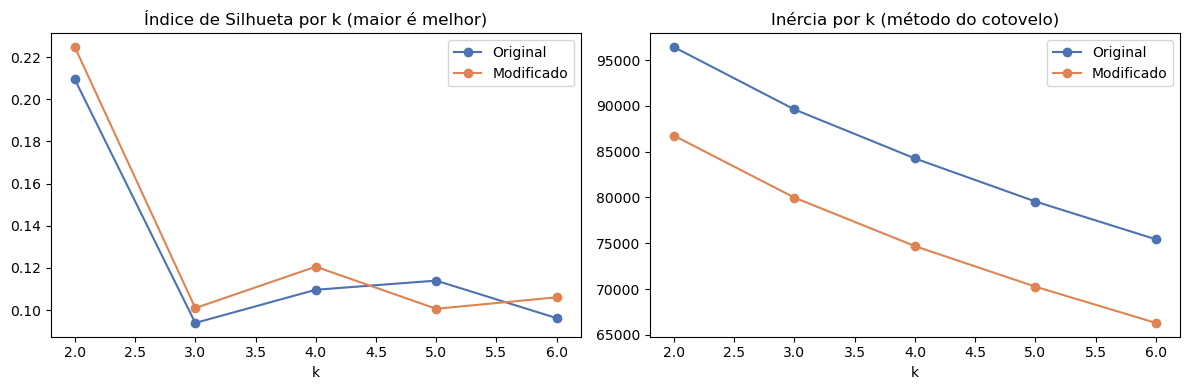

In [22]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

TAM_AMOSTRA = min(10000, X_train_orig.shape[0])
amostra_idx = np.random.RandomState(RANDOM_STATE).choice(X_train_orig.shape[0], size=TAM_AMOSTRA, replace=False)
X_km_orig, X_km_mod = X_train_orig[amostra_idx], X_train_mod[amostra_idx]
y_amostra = y_train.iloc[amostra_idx]          # só para interpretar os grupos (K-Means NÃO usa o y)

def avaliar_kmeans(X, ks=range(2, 7), init="k-means++", n_init=10, max_iter=300, tol=1e-4):
    """Ajusta o K-Means para cada k e devolve silhueta e inércia."""
    linhas = []
    for k in ks:
        km = KMeans(n_clusters=k, init=init, n_init=n_init, max_iter=max_iter, tol=tol, random_state=RANDOM_STATE)
        rotulos = km.fit_predict(X)
        sil = silhouette_score(X, rotulos, sample_size=2000, random_state=RANDOM_STATE)
        linhas.append({"k": k, "Silhueta": sil, "Inércia": km.inertia_})
    return pd.DataFrame(linhas).set_index("k")

km_orig = avaliar_kmeans(X_km_orig)
km_mod  = avaliar_kmeans(X_km_mod)
display(pd.concat({"Original": km_orig, "Modificado": km_mod}, axis=1).round(4))

melhor_k_orig, melhor_sil_orig = km_orig["Silhueta"].idxmax(), km_orig["Silhueta"].max()
melhor_k_mod,  melhor_sil_mod  = km_mod["Silhueta"].idxmax(),  km_mod["Silhueta"].max()
print(f"Melhor k (original)  : {melhor_k_orig} (silhueta {fmt4(melhor_sil_orig)})")
print(f"Melhor k (modificado): {melhor_k_mod} (silhueta {fmt4(melhor_sil_mod)})")

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
for nome, tabela, cor in [("Original", km_orig, "#4c72b0"), ("Modificado", km_mod, "#dd8452")]:
    eixos[0].plot(tabela.index, tabela["Silhueta"], marker="o", label=nome, color=cor)
    eixos[1].plot(tabela.index, tabela["Inércia"], marker="o", label=nome, color=cor)
eixos[0].set_title("Índice de Silhueta por k (maior é melhor)")
eixos[1].set_title("Inércia por k (método do cotovelo)")
for ax in eixos: ax.set_xlabel("k"); ax.legend()
plt.tight_layout(); plt.show()

### 9.3 Quem são os grupos? (cruzando com `y` só para interpretar)
O K-Means não usa o `y`, mas podemos conferir, **depois**, se algum grupo concentra mais clientes que aceitaram.

In [23]:
def perfil_clusters(X, k):
    rotulos = KMeans(n_clusters=k, init="k-means++", n_init=10, max_iter=300,
                     random_state=RANDOM_STATE).fit_predict(X)
    perfil = pd.DataFrame({"cluster": rotulos, "y": y_amostra.values}).groupby("cluster")["y"].agg(
        clientes="size", pct_yes="mean")
    perfil["pct_yes"] = (perfil["pct_yes"] * 100).round(1)
    return perfil

perfil_orig = perfil_clusters(X_km_orig, melhor_k_orig)
perfil_mod  = perfil_clusters(X_km_mod, melhor_k_mod)
print(f"Original (k={melhor_k_orig}):"); display(perfil_orig)
print(f"Modificado (k={melhor_k_mod}):"); display(perfil_mod)
print(f"Referência: % geral de 'yes' na amostra = {y_amostra.mean() * 100:.1f}%")

Original (k=2):


,clientes,pct_yes
cluster,,
0,8305,9.8
1,1695,21.4


Modificado (k=2):


,clientes,pct_yes
cluster,,
0,8302,9.8
1,1698,21.4


Referência: % geral de 'yes' na amostra = 11.8%


In [24]:
dif_sil = melhor_sil_mod - melhor_sil_orig
fraca = max(melhor_sil_orig, melhor_sil_mod) < 0.25
ks_iguais = melhor_k_orig == melhor_k_mod

display(Markdown(f'''
### 9.4 Análise e comparação (K-Means)

**1. Melhor $k$.** No conjunto original o maior índice de silhueta foi com **k = {melhor_k_orig}** (silhueta {fmt4(melhor_sil_orig)}); no modificado, com **k = {melhor_k_mod}** (silhueta {fmt4(melhor_sil_mod)}). {"O melhor k é o mesmo nos dois conjuntos." if ks_iguais else "O melhor k mudou entre os conjuntos."}

**2. Original × modificado.** A diferença de silhueta (modificado − original) é de {fms4(dif_sil)}. {"É uma diferença pequena e foi calculada sobre uma subamostra, então não basta para afirmar que remover `duration` melhora ou piora o agrupamento." if abs(dif_sil) < 0.05 else "A diferença é considerável, sugerindo que `duration` influencia a formação dos grupos."}

**3. Qualidade dos grupos.** {"Silhuetas abaixo de 0,25 indicam grupos pouco separados: os clientes não formam clusters bem definidos, e o melhor k é só uma divisão aproximada." if fraca else "Os valores indicam alguma estrutura de grupos, embora ainda longe de grupos bem separados."}

**4. Relação com o alvo.** O K-Means não usa o `y`. No melhor k do conjunto modificado, a taxa de `yes` por grupo vai de {perfil_mod["pct_yes"].min():.1f}% a {perfil_mod["pct_yes"].max():.1f}% (média geral da amostra: {y_amostra.mean() * 100:.1f}%). Os grupos não foram feitos para separar quem aceita, ao contrário dos classificadores.
'''))


### 9.4 Análise e comparação (K-Means)

**1. Melhor $k$.** No conjunto original o maior índice de silhueta foi com **k = 2** (silhueta 0,2094); no modificado, com **k = 2** (silhueta 0,2247). O melhor k é o mesmo nos dois conjuntos.

**2. Original × modificado.** A diferença de silhueta (modificado − original) é de +0,0153. É uma diferença pequena e foi calculada sobre uma subamostra, então não basta para afirmar que remover `duration` melhora ou piora o agrupamento.

**3. Qualidade dos grupos.** Silhuetas abaixo de 0,25 indicam grupos pouco separados: os clientes não formam clusters bem definidos, e o melhor k é só uma divisão aproximada.

**4. Relação com o alvo.** O K-Means não usa o `y`. No melhor k do conjunto modificado, a taxa de `yes` por grupo vai de 9.8% a 21.4% (média geral da amostra: 11.8%). Os grupos não foram feitos para separar quem aceita, ao contrário dos classificadores.


## 10. Comparação Final e Conclusões

Juntamos os resultados dos três modelos nos dois conjuntos (original, com `duration`, e modificado, sem `duration`). Para cada classificador usamos a **configuração com melhor F1 do `yes` no conjunto modificado** (a mesma nos dois conjuntos, para a comparação ser justa). Como a classe `yes` é minoritária, a leitura principal é feita em **precision, recall e F1 do `yes`**, e não na acurácia.

### 10.1 Tabelas comparativas

In [25]:
def metricas(y_true, y_pred):
    return {
        "Acurácia": accuracy_score(y_true, y_pred),
        "Precision (yes)": precision_score(y_true, y_pred, zero_division=0),
        "Recall (yes)": recall_score(y_true, y_pred),
        "F1 (yes)": f1_score(y_true, y_pred),
    }

print("Random Forest usa:", cfg_rf_final)
print("MLP usa          :", cfg_mlp_final)

linhas = []
for conj in ["Original", "Modificado"]:
    linhas.append({"Modelo": "Random Forest", "Conjunto": conj, **metricas(y_test, previsoes_rf[(cfg_rf_final, conj)])})
for conj in ["Original", "Modificado"]:
    linhas.append({"Modelo": "MLP", "Conjunto": conj, **metricas(y_test, previsoes_mlp[(cfg_mlp_final, conj)])})

final = pd.DataFrame(linhas).set_index(["Modelo", "Conjunto"])
display(final.round(3))

var = final.xs("Modificado", level="Conjunto") - final.xs("Original", level="Conjunto")
print("Variação ao remover duration (modificado - original):")
display(var.round(3))

km = pd.DataFrame({
    "Conjunto": ["Original", "Modificado"],
    "Melhor k": [melhor_k_orig, melhor_k_mod],
    "Silhueta": [round(melhor_sil_orig, 4), round(melhor_sil_mod, 4)],
})
display(km)

Random Forest usa: C - Profunda balanceada (200)
MLP usa          : B - Profunda (128,64, relu)


Acurácia  Precision (yes)  Recall (yes)  F1 (yes)
Modelo        Conjunto                                                     
Random Forest Original       0.879            0.489         0.790     0.604
              Modificado     0.868            0.445         0.531     0.484
MLP           Original       0.907            0.609         0.566     0.587
              Modificado     0.895            0.608         0.279     0.383

Variação ao remover duration (modificado - original):


,Acurácia,Precision (yes),Recall (yes),F1 (yes)
Modelo,,,,
Random Forest,-0.011,-0.044,-0.258,-0.120
MLP,-0.012,-0.002,-0.287,-0.205


,Conjunto,Melhor k,Silhueta
0,Original,2,0.2094
1,Modificado,2,0.2247


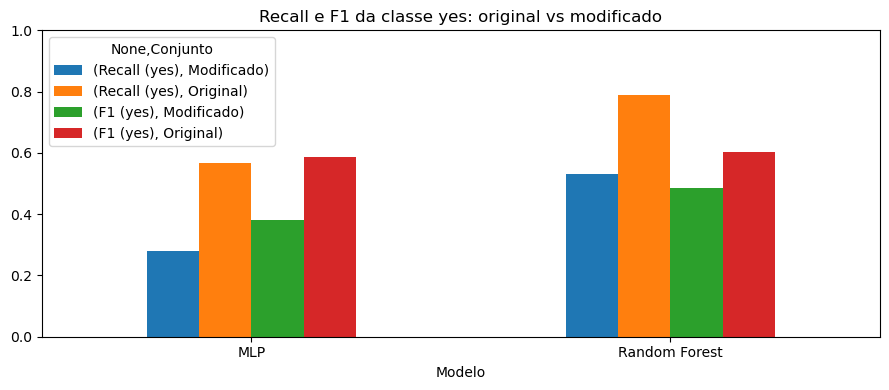

In [26]:
final[["Recall (yes)", "F1 (yes)"]].unstack("Conjunto").plot(kind="bar", figsize=(9, 4), rot=0)
plt.title("Recall e F1 da classe yes: original vs modificado")
plt.ylim(0, 1); plt.tight_layout(); plt.show()

In [27]:
fo = final.xs("Original", level="Conjunto"); fm = final.xs("Modificado", level="Conjunto")
linhas_modelos = ""
for m in ["Random Forest", "MLP"]:
    linhas_modelos += (f"- **{m}:** recall do `yes` {fmt(fo.loc[m, 'Recall (yes)'])} → {fmt(fm.loc[m, 'Recall (yes)'])} "
                       f"({fms(var.loc[m, 'Recall (yes)'])}); F1 do `yes` {fmt(fo.loc[m, 'F1 (yes)'])} → {fmt(fm.loc[m, 'F1 (yes)'])} "
                       f"({fms(var.loc[m, 'F1 (yes)'])}); precision {fmt(fo.loc[m, 'Precision (yes)'])} → {fmt(fm.loc[m, 'Precision (yes)'])}.\n")

melhor_o, melhor_m = fo["F1 (yes)"].idxmax(), fm["F1 (yes)"].idxmax()
outro_m = "MLP" if melhor_m == "Random Forest" else "Random Forest"
rec_best, pre_best = fm.loc[melhor_m, "Recall (yes)"], fm.loc[melhor_m, "Precision (yes)"]

display(Markdown(f'''
### 10.2 Análise dos resultados

**1. A acurácia não diferencia bem os modelos.** Ficou entre {fmt(final["Acurácia"].min())} e {fmt(final["Acurácia"].max())}, perto dos {fmt(1 - y_test.mean())} de um modelo que sempre responde `no`. A diferença está no recall e no F1 do `yes`.

**2. Efeito de remover `duration` em cada classificador** (original → modificado):

{linhas_modelos}
**3. Qual modelo foi melhor.** Pelo F1 do `yes`, o melhor no conjunto original foi **{melhor_o}** e, no modificado, **{melhor_m}** (F1 {fmt(fm.loc[melhor_m, "F1 (yes)"])} contra {fmt(fm.loc[outro_m, "F1 (yes)"])} do {outro_m}). As conclusões dependem das configurações testadas (três por modelo, sem busca exaustiva) e foram escolhidas olhando o conjunto de teste.

**4. K-Means.** O melhor k foi {melhor_k_orig} no original (silhueta {fmt4(melhor_sil_orig)}) e {melhor_k_mod} no modificado (silhueta {fmt4(melhor_sil_mod)}). {"Silhueta abaixo de 0,25 indica grupos pouco separados" if max(melhor_sil_orig, melhor_sil_mod) < 0.25 else "Os valores indicam alguma estrutura de grupos"}, e a diferença entre os conjuntos é {"pequena" if abs(melhor_sil_mod - melhor_sil_orig) < 0.05 else "relevante"}.

### 10.3 Conclusão

O `duration` é o atributo mais informativo do dataset, mas só se conhece depois da ligação (*data leakage*). Por isso os resultados do conjunto original estão inflados, e o conjunto modificado representa o uso real. Nesse cenário realista, o melhor modelo ({melhor_m}) encontra cerca de **{rec_best * 100:.0f}%** dos clientes que aceitariam, com precision de **{pre_best * 100:.0f}%**. O resultado mostra o quanto o desempenho aparente dependia de uma informação que não existe no momento da decisão.
'''))


### 10.2 Análise dos resultados

**1. A acurácia não diferencia bem os modelos.** Ficou entre 0,868 e 0,907, perto dos 0,883 de um modelo que sempre responde `no`. A diferença está no recall e no F1 do `yes`.

**2. Efeito de remover `duration` em cada classificador** (original → modificado):

- **Random Forest:** recall do `yes` 0,790 → 0,531 (-0,258); F1 do `yes` 0,604 → 0,484 (-0,120); precision 0,489 → 0,445.
- **MLP:** recall do `yes` 0,566 → 0,279 (-0,287); F1 do `yes` 0,587 → 0,383 (-0,205); precision 0,609 → 0,608.

**3. Qual modelo foi melhor.** Pelo F1 do `yes`, o melhor no conjunto original foi **Random Forest** e, no modificado, **Random Forest** (F1 0,484 contra 0,383 do MLP). As conclusões dependem das configurações testadas (três por modelo, sem busca exaustiva) e foram escolhidas olhando o conjunto de teste.

**4. K-Means.** O melhor k foi 2 no original (silhueta 0,2094) e 2 no modificado (silhueta 0,2247). Silhueta abaixo de 0,25 indica grupos pouco separados, e a diferença entre os conjuntos é pequena.

### 10.3 Conclusão

O `duration` é o atributo mais informativo do dataset, mas só se conhece depois da ligação (*data leakage*). Por isso os resultados do conjunto original estão inflados, e o conjunto modificado representa o uso real. Nesse cenário realista, o melhor modelo (Random Forest) encontra cerca de **53%** dos clientes que aceitariam, com precision de **45%**. O resultado mostra o quanto o desempenho aparente dependia de uma informação que não existe no momento da decisão.
